In [1]:
%pip install qiskit qiskit-machine-learning qiskit-algorithms qiskit-aer opencv-python tensorflow matplotlib

import numpy as np
import cv2
from tensorflow.keras.datasets import mnist
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Estimator as AerEstimator
from IPython.display import clear_output
import matplotlib.pyplot as plt

print("Imports successful.")


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Imports successful.


In [2]:
# Load MNIST
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Filter for 3 and 6
train_filter = np.where((y_train == 3) | (y_train == 6))
test_filter = np.where((y_test == 3) | (y_test == 6))
x_train, y_train = x_train[train_filter], y_train[train_filter]
x_test, y_test = x_test[test_filter], y_test[test_filter]

# Downscale to 4x4 and Binarize
def preprocess(images):
    processed = []
    for img in images:
        resized = cv2.resize(img, (4, 4))
        normalized = resized / 255.0
        binarized = np.where(normalized > 0.5, 1.0, 0.0)
        processed.append(binarized.flatten()) # Flattens to 16 pixels
    return np.array(processed)

x_train_final = preprocess(x_train)
x_test_final = preprocess(x_test)

# Hinge labels: 3 -> 1.0, 6 -> -1.0
y_train_hinge = np.where(y_train == 3, 1.0, -1.0)
y_test_hinge = np.where(y_test == 3, 1.0, -1.0)

print(f"Data ready. Training shapes: {x_train_final.shape}, {y_train_hinge.shape}")

Data ready. Training shapes: (12049, 16), (12049,)


In [3]:
# 1. Feature Map (Data Encoding)
feature_map = QuantumCircuit(17) 
input_params = ParameterVector('img', 16)
for i in range(16):
    feature_map.rx(input_params[i] * np.pi, i)

# 2. PQC Ansatz (XX and ZZ Layers)
ansatz = QuantumCircuit(17)
ansatz.x(16)
ansatz.h(16)
xx_params = ParameterVector('xx1', 16)
zz_params = ParameterVector('zz1', 16)

for i in range(16):
    ansatz.rxx(xx_params[i], i, 16)
for i in range(16):
    ansatz.rzz(zz_params[i], i, 16)
ansatz.h(16)

# 3. Combine into full_circuit
full_circuit = feature_map.compose(ansatz)
observable = SparsePauliOp.from_list([("Z" + "I"*16, 1)])

print("17-Qubit Circuit built successfully.")

17-Qubit Circuit built successfully.


In [5]:
from qiskit_aer.primitives import EstimatorV2
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import COBYLA
from IPython.display import clear_output
import matplotlib.pyplot as plt

# 1. Setup Hardware-Accelerated Aer Estimator using the V2 architecture
aer_estimator = EstimatorV2()

# 2. Setup QNN
qnn = EstimatorQNN(
    circuit=full_circuit,
    observables=observable,
    input_params=input_params,
    weight_params=ansatz.parameters,
    estimator=aer_estimator 
)

# 3. Setup Live Plotting Callback
loss_history = []
def monitor_training(weights, loss):
    clear_output(wait=True)
    loss_history.append(loss)
    plt.plot(loss_history, label="Training Loss")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

# 4. Initialize Classifier
classifier = NeuralNetworkClassifier(
    neural_network=qnn,
    optimizer=COBYLA(maxiter=100), 
    loss="squared_error",
    callback=monitor_training
)

# 5. Execute Micro-Batch
# print("Starting training on micro-batch...")
# classifier.fit(x_train_final[:20], y_train_hinge[:20])
# 5. Execute Full Dataset Overnight
print("Starting training on the full dataset...")
classifier.fit(x_train_final, y_train_hinge)

# 6. Automatically save the model and weights when training completes
print("Training finished! Saving model...")

# Primary: Save the full classifier object (circuit, optimizer state, and weights)
classifier.save("qnn_model_full.model")

# Failsafe: Save just the raw numerical weights to a standard NumPy array
import numpy as np
np.save("qnn_weights_full.npy", classifier.weights)

print("Model saved successfully. Safe to close notebook.")

Starting training on the full dataset...


KeyboardInterrupt: 

In [10]:
import numpy as np

# 1. Score the model on the unseen testing data
print("Scoring model against the test dataset...")
accuracy = classifier.score(x_test_final, y_test_hinge)
print(f"Final Test Accuracy: {accuracy * 100:.2f}%")

# 2. Generate predictions for the first 10 test images
predictions = classifier.predict(x_test_final[:10])

# Map the hinge loss [-1, 1] back to the original digits [6, 3] for readability
predicted_digits = np.where(predictions.flatten() > 0, 3, 6)
actual_digits = np.where(y_test_hinge[:10] > 0, 3, 6)

print("\n--- Sample Predictions ---")
print(f"Predicted Output: {predicted_digits}")
print(f"Actual Digits:    {actual_digits}")

Scoring model against the test dataset...
Final Test Accuracy: 78.05%

--- Sample Predictions ---
Predicted Output: [3 6 6 3 6 6 6 6 3 6]
Actual Digits:    [6 3 6 6 3 3 3 6 3 6]


In [11]:
import numpy as np

# 1. Calculate overall Training and Validation Accuracies
# This corresponds to the paper's 0.8603 (training) and 0.8669 (validation)
train_accuracy = classifier.score(x_train_final, y_train_hinge)
val_accuracy = classifier.score(x_test_final, y_test_hinge)

print("--- Overall Model Performance ---")
print(f"Training Hinge Accuracy:   {train_accuracy:.4f} (Paper: 0.8603)")
print(f"Validation Hinge Accuracy: {val_accuracy:.4f} (Paper: 0.8669)")

# 2. Recreate the Paper's 100-Image Test Set
# The paper tested exactly 53 images of '3' and 47 images of '6'
indices_3 = np.where(y_test_hinge == 1.0)[0]
indices_6 = np.where(y_test_hinge == -1.0)[0]

# Extract the exact counts
x_test_100 = np.vstack((x_test_final[indices_3[:53]], x_test_final[indices_6[:47]]))
y_test_100 = np.concatenate((y_test_hinge[indices_3[:53]], y_test_hinge[indices_6[:47]]))

# 3. Evaluate the 100-Image Subset
predictions_100 = classifier.predict(x_test_100).flatten()

# Calculate specific accuracies
acc_3 = np.mean(predictions_100[:53] == y_test_100[:53])
acc_6 = np.mean(predictions_100[53:] == y_test_100[53:])
total_acc = np.mean(predictions_100 == y_test_100)

print("\n--- 100-Image Subset Testing (Paper Target: 100%) ---")
print(f"Number 3 Accuracy (53 images): {acc_3 * 100:.1f}%")
print(f"Number 6 Accuracy (47 images): {acc_6 * 100:.1f}%")
print(f"Total Testing Accuracy:        {total_acc * 100:.1f}%")

--- Overall Model Performance ---
Training Hinge Accuracy:   0.7862 (Paper: 0.8603)
Validation Hinge Accuracy: 0.7810 (Paper: 0.8669)

--- 100-Image Subset Testing (Paper Target: 100%) ---
Number 3 Accuracy (53 images): 45.3%
Number 6 Accuracy (47 images): 83.0%
Total Testing Accuracy:        63.0%


In [12]:
import numpy as np

# Load the saved weights (ensure the filename matches what you saved)
loaded_weights = np.load("qnn_weights_full.npy")

# Check the array shape (should be 32) and print the values
print(f"Weight Array Shape: {loaded_weights.shape}")
print("\nOptimized Parameters (in radians):")
print(loaded_weights)

Weight Array Shape: (32,)

Optimized Parameters (in radians):
[ 2.0740533  -1.05210701  2.16113778  0.849318   -0.56871003  0.98006732
  0.03392229  0.58969533 -0.55518744  2.64577793  1.23872257  1.27543495
  0.15196988  0.94936733  0.6153672   1.36572636  2.79671332  0.0089493
  0.11778127 -0.12241091  0.25861394  0.0693155   1.18702774 -0.04803167
  0.14893519  0.36996612 -0.01986775  0.02722727  0.38514291  0.13419236
  0.09442698 -0.10356102]


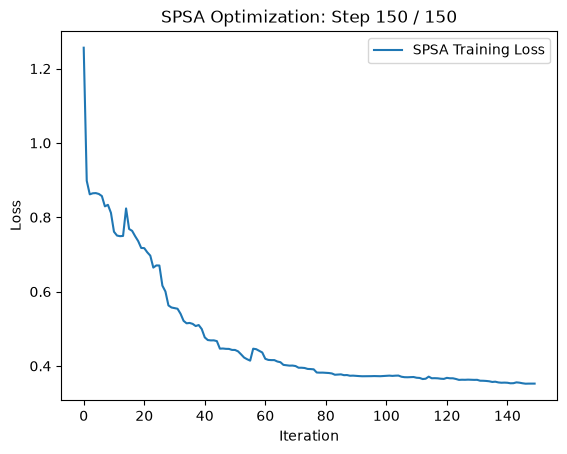

Training finished! Saving final model...
Complete. Safe to close notebook.


C:\Users\asus\AppData\Local\Temp\ipykernel_1588\3080279181.py:76: DeprecationWarning: SerializableModelMixin.save() is deprecated. as of qiskit-machine-learning 0.9.0 and will be removed no sooner than 4 months after the release date. Use the to_dill() method instead.
  classifier.save("victus_qnn_model_spsa_full.model")


In [4]:
from qiskit_aer.primitives import EstimatorV2
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import SPSA
from IPython.display import clear_output
import matplotlib.pyplot as plt
import csv
import numpy as np

# 1. Setup Hardware-Accelerated Aer Estimator using the V2 architecture
aer_estimator = EstimatorV2()

# 2. Setup QNN
qnn = EstimatorQNN(
    circuit=full_circuit,
    observables=observable,
    input_params=input_params,
    weight_params=ansatz.parameters,
    estimator=aer_estimator 
)

# 3. Setup Live Plotting & Checkpointing Callback
checkpoint_file = "victus_spsa_checkpoints.csv"
with open(checkpoint_file, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Iteration", "Loss", "Weights"])

loss_history = []
iteration_count = 0


def monitor_spsa_training(*args):
    global iteration_count
    iteration_count += 1
    
    # SPSA passes 5 arguments: (nfev, weights, loss, stepsize, accepted)
    if len(args) == 5:
        weights = args[1]
        loss = args[2]
    # Fallback for standard classifier signature (weights, loss)
    elif len(args) == 2:
        weights = args[0]
        loss = args[1]
    else:
        return

    loss_history.append(loss)
    
    # Save parameters to hard drive safely
    with open(checkpoint_file, mode='a', newline='') as file:
        writer = csv.writer(file)
        writer.writerow([iteration_count, loss, weights.tolist()])
        
    clear_output(wait=True)
    plt.plot(loss_history, label="SPSA Training Loss")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title(f"SPSA Optimization: Step {iteration_count} / 150")
    plt.legend()
    plt.show()

# 4. Initialize Classifier
classifier = NeuralNetworkClassifier(
    neural_network=qnn,
    optimizer=SPSA(maxiter=150), 
    loss="squared_error",
    callback=monitor_spsa_training
)

# 5. Execute Full Dataset
print("Starting SPSA training on the full dataset...")
classifier.fit(x_train_final, y_train_hinge)

# 6. Save final models to disk
print("Training finished! Saving final model...")
classifier.save("victus_qnn_model_spsa_full.model")
np.save("victus_qnn_weights_spsa_full.npy", classifier.weights)
print("Complete. Safe to close notebook.")

In [5]:
print("Calculating forward pass on the full testing set...")
test_accuracy = classifier.score(x_test_final, y_test_hinge)
print(f"Total Testing Accuracy: {test_accuracy * 100:.1f}%")

Calculating forward pass on the full testing set...
Total Testing Accuracy: 87.9%


In [6]:
print("Evaluating the 100-image benchmark...")
subset_x = x_test_final[:100]
subset_y = y_test_hinge[:100]

predictions = classifier.predict(subset_x)
correct = sum(1 for p, y in zip(predictions, subset_y) if p == y)
print(f"Benchmark Subset Accuracy: {correct}%")

Evaluating the 100-image benchmark...
Benchmark Subset Accuracy: 88%


In [7]:
import numpy as np

# 1. Forward pass to get raw continuous outputs [-1.0 to 1.0]
print("Extracting continuous Z-axis expectation values...")
raw_outputs = qnn.forward(x_test_final, classifier.weights).flatten()

# 2. Calculate Hinge Loss: max(0, 1 - y_true * y_pred)
hinge_losses = np.maximum(0, 1 - (y_test_hinge * raw_outputs))
mean_hinge_loss = np.mean(hinge_losses)

# 3. Calculate Hinge Accuracy (Predictions based on strict margin sign)
hinge_predictions = np.where(raw_outputs >= 0, 1, -1)
hinge_accuracy = np.mean(hinge_predictions == y_test_hinge)

print(f"Mean Hinge Loss: {mean_hinge_loss:.4f}")
print(f"Final Hinge Accuracy: {hinge_accuracy * 100:.1f}%")

Extracting continuous Z-axis expectation values...
Mean Hinge Loss: 0.4336
Final Hinge Accuracy: 87.9%


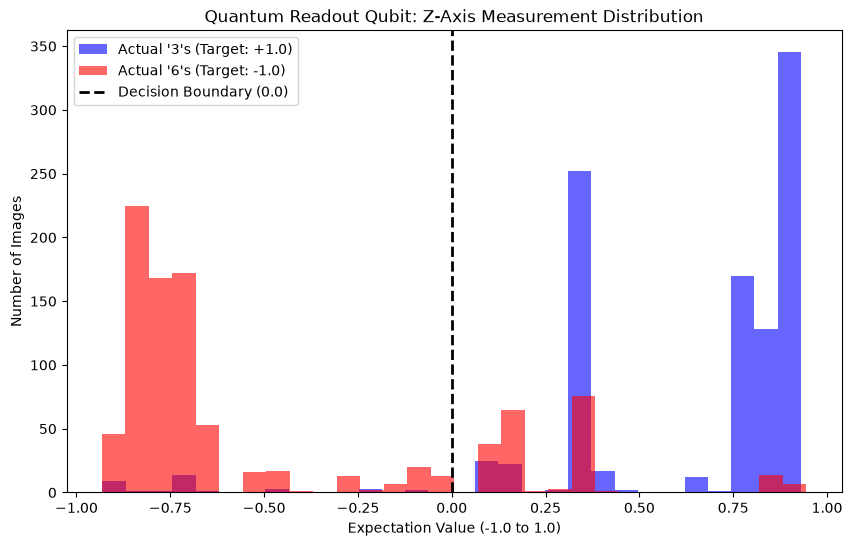

In [8]:
import matplotlib.pyplot as plt

# Separate the raw continuous outputs by their actual labels
outputs_3 = raw_outputs[y_test_hinge == 1]
outputs_6 = raw_outputs[y_test_hinge == -1]

plt.figure(figsize=(10, 6))
plt.hist(outputs_3, bins=30, alpha=0.6, color='blue', label="Actual '3's (Target: +1.0)")
plt.hist(outputs_6, bins=30, alpha=0.6, color='red', label="Actual '6's (Target: -1.0)")
plt.axvline(x=0, color='black', linestyle='--', linewidth=2, label="Decision Boundary (0.0)")

plt.title("Quantum Readout Qubit: Z-Axis Measurement Distribution")
plt.xlabel("Expectation Value (-1.0 to 1.0)")
plt.ylabel("Number of Images")
plt.legend()
plt.show()